# 1. Exploring the sales data

Five years (2013–2017) of daily unit sales for 50 items in 10 stores: 500 store-item SKUs.

In [1]:
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import pandas as pd

from src.config import PROCESSED
plt.rcParams['figure.dpi'] = 110
from src.data import load_sales

sales = load_sales()
print(sales.shape, sales.date.min().date(), 'to', sales.date.max().date())
print(sales.groupby(['store', 'item']).ngroups, 'SKUs, no missing values:', not sales.isna().any().any())

(913000, 4) 2013-01-01 to 2017-12-31
500 SKUs, no missing values: True


## Demand is growing, with strong yearly and weekly seasonality

The growth matters for inventory: a safety stock built on the five-year average demand will be sized for a smaller business than the one running today.

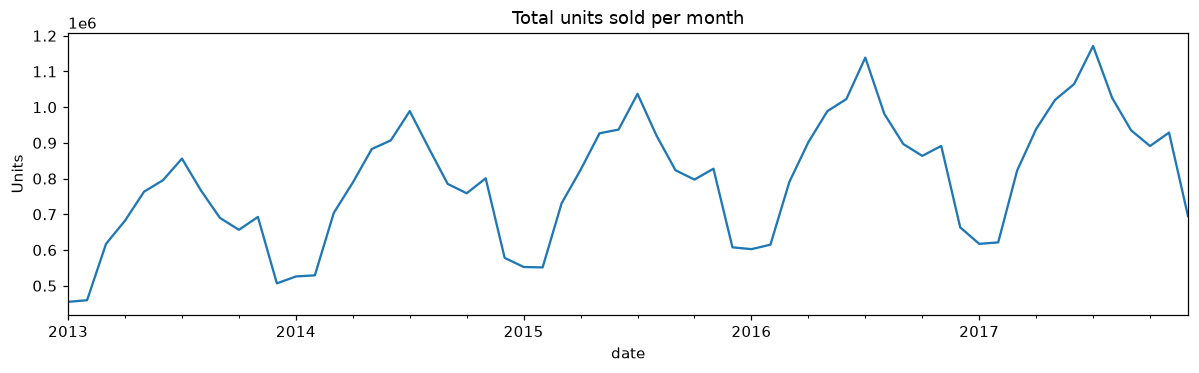

In [2]:
monthly = sales.set_index('date').sales.resample('MS').sum()
ax = monthly.plot(figsize=(11, 3.5), title='Total units sold per month')
ax.set_ylabel('Units'); plt.tight_layout()

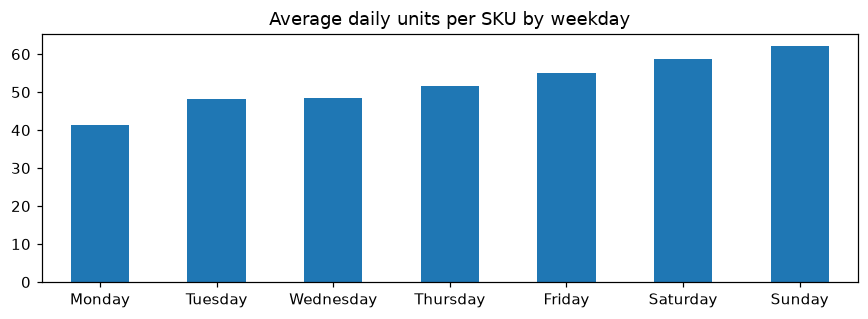

In [3]:
weekday = sales.groupby(sales.date.dt.day_name()).sales.mean()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
ax = weekday.reindex(order).plot.bar(figsize=(8, 3), title='Average daily units per SKU by weekday', rot=0)
ax.set_xlabel(''); plt.tight_layout()

## Three example SKUs

These three are used as examples in later notebooks; every analysis runs on all 500.

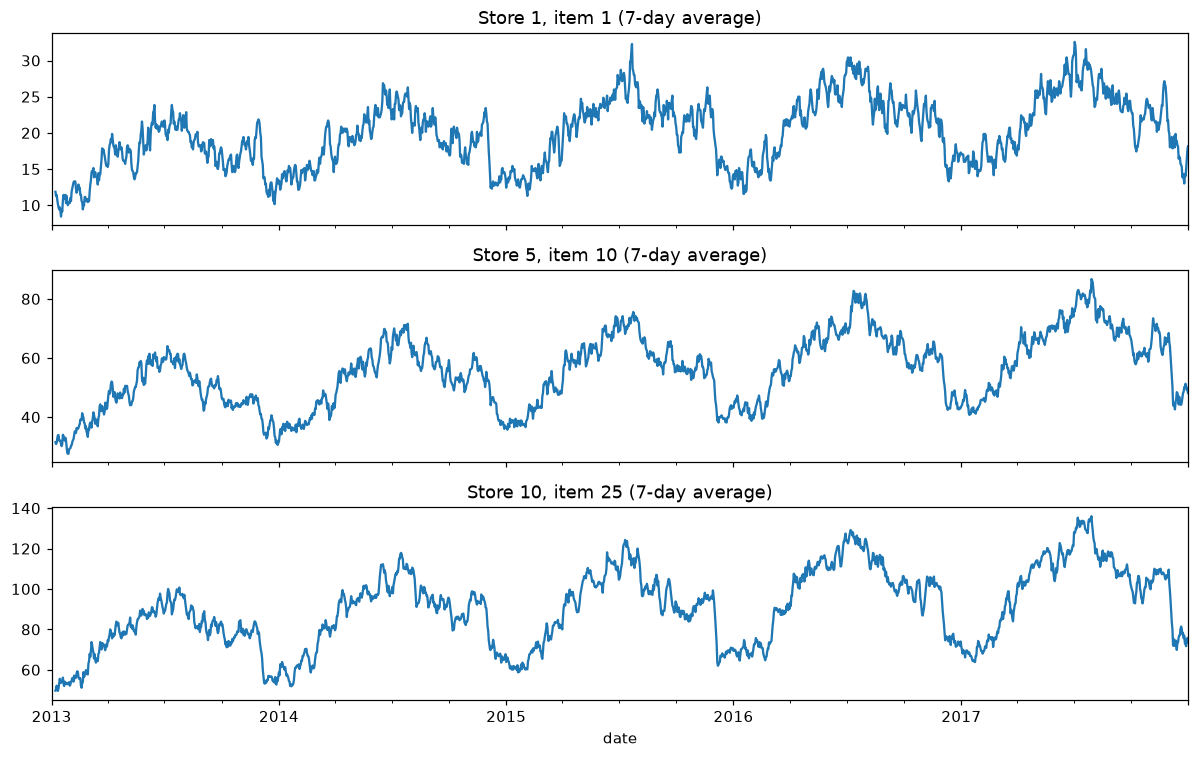

In [4]:
SHOWCASE = [(1, 1), (5, 10), (10, 25)]
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (store, item) in zip(axes, SHOWCASE):
    s = sales[(sales.store == store) & (sales.item == item)].set_index('date').sales
    s.rolling(7).mean().plot(ax=ax, title=f'Store {store}, item {item} (7-day average)')
plt.tight_layout()